# 09 - Attention-BiLSTM Model

## Objective
Develop an Attention-BiLSTM model to classify multilingual civic complaints into 12 categories.

## Model Architecture
- Pretrained Word2Vec Embeddings (100 dimensions)
- Bidirectional LSTM (64 units in each direction)
- Attention Mechanism
- Dropout (0.3)
- Dense Output Layer (12 classes, Softmax)

## Training Configuration
- Optimizer: Adam
- Loss: Sparse Categorical Crossentropy
- Batch Size: 64
- Maximum Epochs: 15
- Early Stopping: Patience 3

## Evaluation
Accuracy, Precision, Recall, F1-score and Confusion Matrix.

In [1]:
# Import libraries required for data loading and model development
import os
import pickle
import numpy as np
import pandas as pd
import tensorflow as tf

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Load the tokenizer and label encoder
with open("../models/preprocessing/tokenizer.pkl", "rb") as file:
    tokenizer = pickle.load(file)

with open("../models/preprocessing/label_encoder.pkl", "rb") as file:
    label_encoder = pickle.load(file)

# Load the maximum sequence length
MAX_LEN = int(np.load("../models/preprocessing/max_len.npy"))

# Load the existing train, validation and test splits
data = np.load("../models/preprocessing/tokenized_data.npz")

X_train_padded = data["X_train"]
X_val_padded = data["X_val"]
X_test_padded = data["X_test"]

y_train = data["y_train"]
y_val = data["y_val"]
y_test = data["y_test"]

# Load the pretrained Word2Vec embedding matrix
embedding_matrix = np.load(
    "../models/embeddings/word2vec_embedding_matrix.npy"
)

# Define model configuration
VOCAB_SIZE = len(tokenizer.word_index) + 1
EMBEDDING_DIM = embedding_matrix.shape[1]
NUM_CLASSES = len(label_encoder.classes_)

# Display the loaded configuration and dataset shapes
print("Vocabulary Size:", VOCAB_SIZE)
print("Embedding Dimension:", EMBEDDING_DIM)
print("Maximum Sequence Length:", MAX_LEN)
print("Number of Classes:", NUM_CLASSES)

print("\nTraining Shape:", X_train_padded.shape, y_train.shape)
print("Validation Shape:", X_val_padded.shape, y_val.shape)
print("Testing Shape:", X_test_padded.shape, y_test.shape)

Vocabulary Size: 20089
Embedding Dimension: 100
Maximum Sequence Length: 156
Number of Classes: 12

Training Shape: (11563, 156) (11563,)
Validation Shape: (2478, 156) (2478,)
Testing Shape: (2478, 156) (2478,)


In [2]:
# Import TensorFlow and Keras components for the custom attention layer
from tensorflow.keras.layers import Layer
import tensorflow.keras.backend as K

# Define a custom attention layer to calculate importance weights
class Attention(Layer):

    def __init__(self, **kwargs):
        super(Attention, self).__init__(**kwargs)

    # Create trainable weights for calculating attention scores
    def build(self, input_shape):
        self.W = self.add_weight(
            name="attention_weight",
            shape=(input_shape[-1], 1),
            initializer="glorot_uniform",
            trainable=True
        )

        self.b = self.add_weight(
            name="attention_bias",
            shape=(input_shape[1], 1),
            initializer="zeros",
            trainable=True
        )

        super(Attention, self).build(input_shape)

    # Calculate attention scores and combine BiLSTM outputs
    def call(self, inputs):
        # Calculate importance scores for each time step
        score = K.tanh(K.dot(inputs, self.W) + self.b)

        # Normalize scores into attention weights
        attention_weights = K.softmax(score, axis=1)

        # Apply attention weights to the BiLSTM outputs
        context_vector = inputs * attention_weights

        # Sum weighted outputs into a context vector
        context_vector = K.sum(context_vector, axis=1)

        return context_vector

In [3]:
# Import the layers required to build the Attention-BiLSTM model
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Embedding, LSTM, Bidirectional, Dropout, Dense
)

# Define the input layer for padded complaint sequences
inputs = Input(shape=(MAX_LEN,))

# Load pretrained Word2Vec embeddings
embedding_layer = Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    weights=[embedding_matrix],
    mask_zero=True,
    trainable=True
)(inputs)

# Extract contextual features using BiLSTM
bilstm_output = Bidirectional(
    LSTM(64, return_sequences=True)
)(embedding_layer)

# Apply attention to focus on important sequence positions
attention_output = Attention()(bilstm_output)

# Apply dropout to reduce overfitting
dropout_output = Dropout(0.3)(attention_output)

# Predict probabilities for the 12 complaint categories
outputs = Dense(NUM_CLASSES, activation="softmax")(dropout_output)

# Create the Attention-BiLSTM model
attention_bilstm_model = Model(
    inputs=inputs,
    outputs=outputs
)

# Compile the model for multiclass classification
attention_bilstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the model architecture and parameter counts
attention_bilstm_model.summary()

c:\Project\civic_sense\.venv\Lib\site-packages\keras\src\layers\layer.py:1039: UserWarning: Layer 'attention' (of type Attention) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 156)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 156, 100)  │  2,008,900 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 156)       │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 156, 128)  │     84,480 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ (None, 128)       │        284 │ bidirectional[0]… │
│ (Attention)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 12)        │      1,548 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,095,212 (7.99 MB)

 Trainable params: 2,095,212 (7.99 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Import EarlyStopping to prevent unnecessary training
from tensorflow.keras.callbacks import EarlyStopping

# Stop training if validation loss does not improve for 3 epochs
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Train the Attention-BiLSTM model using the same configuration
history = attention_bilstm_model.fit(
    X_train_padded,
    y_train,
    validation_data=(X_val_padded, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 21s 106ms/step - accuracy: 0.6049 - loss: 1.4514 - val_accuracy: 0.7300 - val_loss: 0.9802
Epoch 2/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 19s 105ms/step - accuracy: 0.7834 - loss: 0.8529 - val_accuracy: 0.7760 - val_loss: 0.8041
Epoch 3/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - accuracy: 0.8286 - loss: 0.6823 - val_accuracy: 0.8010 - val_loss: 0.7237
Epoch 4/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 21s 115ms/step - accuracy: 0.8518 - loss: 0.5741 - val_accuracy: 0.8035 - val_loss: 0.7014
Epoch 5/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 21s 117ms/step - accuracy: 0.8711 - loss: 0.4963 - val_accuracy: 0.8019 - val_loss: 0.7042
Epoch 6/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 21s 116ms/step - accuracy: 0.8877 - loss: 0.4345 - val_accuracy: 0.8156 - val_loss: 0.6801
Epoch 7/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 21s 117ms/step - accuracy: 0.9060 - loss: 0.3567 - val_accuracy: 0.8095 - val_loss: 0.6947
Epoch 8/15
181/181 ━━━━━━━━━━━━━━━━━━━━ 22s 120ms/step - accuracy: 0.9200 - loss: 0

In [5]:
# Evaluate the restored Attention-BiLSTM model on training and validation data
train_loss, train_accuracy = attention_bilstm_model.evaluate(
    X_train_padded, y_train, verbose=0
)

val_loss, val_accuracy = attention_bilstm_model.evaluate(
    X_val_padded, y_val, verbose=0
)

# Display the final metrics using the restored best weights
print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Training Loss: {train_loss:.4f}")

print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Loss: {val_loss:.4f}")

Training Accuracy: 0.9031
Training Loss: 0.3585
Validation Accuracy: 0.8156
Validation Loss: 0.6801


In [6]:
# Generate class probabilities for the validation dataset
y_val_prob = attention_bilstm_model.predict(X_val_padded)

# Convert predicted probabilities into class labels
y_val_pred = np.argmax(y_val_prob, axis=1)

# Generate the category-wise precision, recall and F1-score report
print(classification_report(
    y_val,
    y_val_pred,
    target_names=label_encoder.classes_,
    digits=4,
    zero_division=0
))

78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step
                                       precision    recall  f1-score   support

                    Animal Management     0.9098    0.9308    0.9202       130
Civic Infrastructure and Encroachment     0.6000    0.1667    0.2609        36
                Drainage and Sewerage     0.6466    0.4967    0.5618       151
            Electricity and Utilities     0.7692    0.7317    0.7500        41
        Environment and Public Spaces     0.7041    0.6053    0.6509       114
                        Public Safety     0.6667    0.0667    0.1212        30
                    Public Sanitation     0.8333    0.7639    0.7971        72
                  Road Infrastructure     0.7919    0.9031    0.8439       784
                      Street Lighting     0.8937    0.8371    0.8645       221
                Traffic and Transport     0.6784    0.7759    0.7239       174
                     Waste Management     0.9038    0.8724    0.8878       635
           

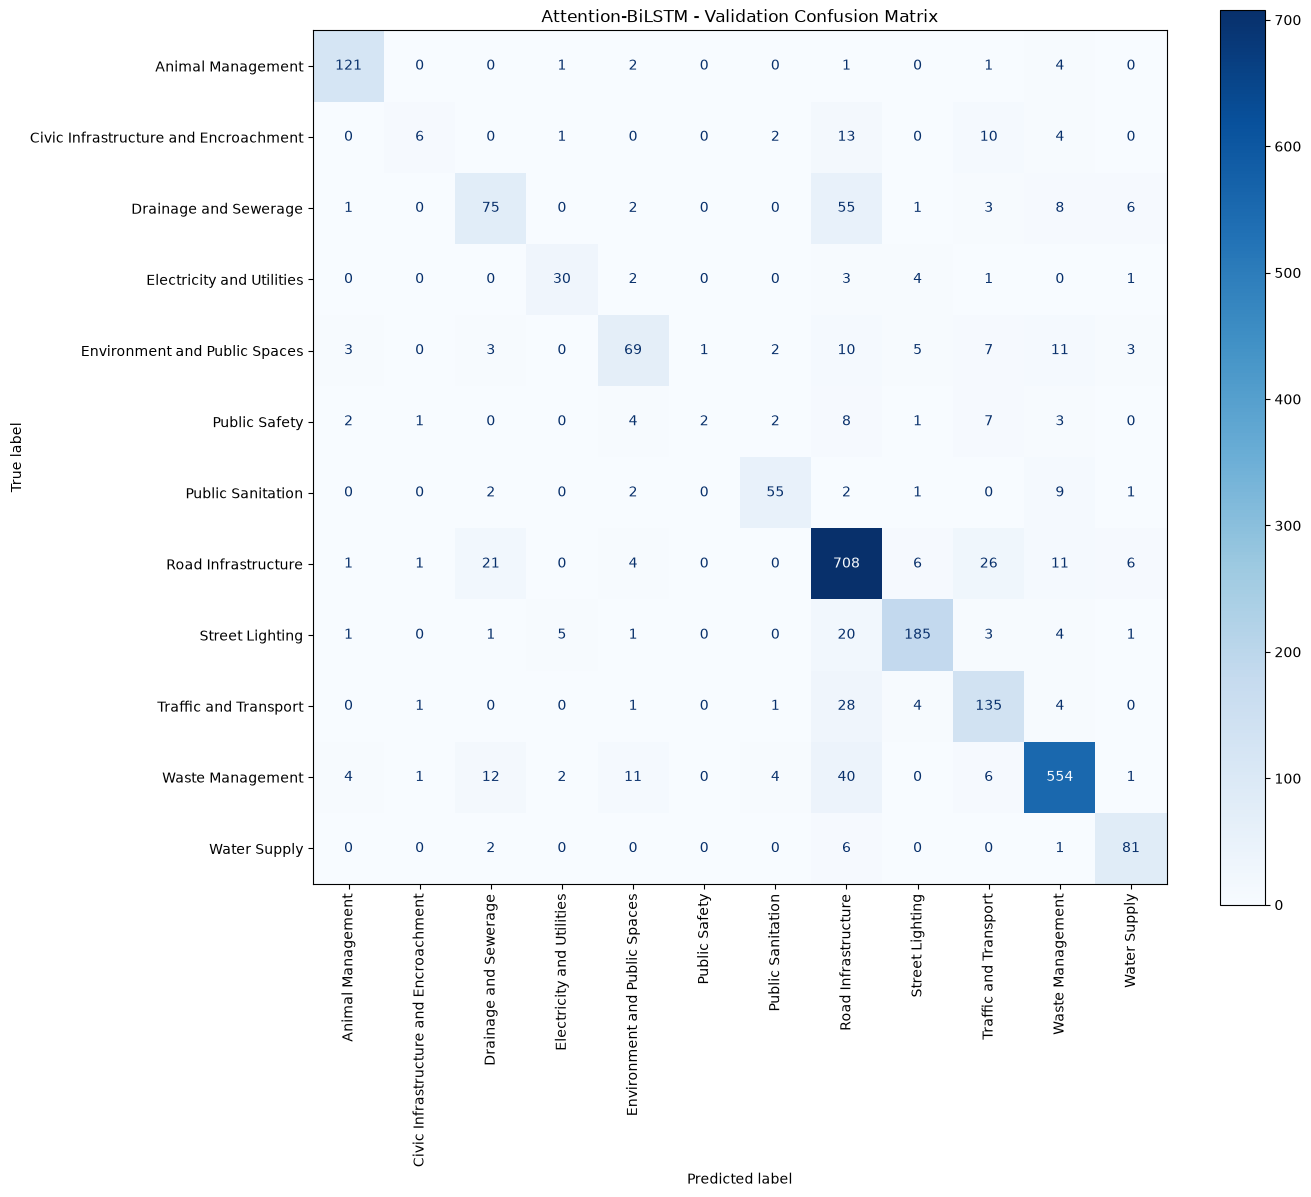

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
# Calculate the confusion matrix using Attention-BiLSTM validation predictions
cm = confusion_matrix(y_val, y_val_pred)

# Create a labelled confusion matrix for all 12 categories
plt.figure(figsize=(14, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

# Display the confusion matrix with category labels
disp.plot(
    cmap="Blues",
    xticks_rotation=90,
    values_format="d",
    ax=plt.gca()
)

plt.title("Attention-BiLSTM - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [11]:
# Create a directory to store Attention-BiLSTM experiment results
save_dir = "../models/experiments/attention_bilstm"
os.makedirs(save_dir, exist_ok=True)

# Save the trained Attention-BiLSTM model
attention_bilstm_model.save(
    os.path.join(save_dir, "attention_bilstm_word2vec.keras")
)

# Save the training history
pd.DataFrame(history.history).to_csv(
    os.path.join(save_dir, "training_history.csv"),
    index=False
)

# Generate and save the validation classification report
report = classification_report(
    y_val,
    y_val_pred,
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    os.path.join(save_dir, "validation_classification_report.csv")
)

# Confirm that the experiment files have been saved
print("Attention-BiLSTM experiment saved successfully!")
print("Saved directory:", save_dir)

Attention-BiLSTM experiment saved successfully!
Saved directory: ../models/experiments/attention_bilstm


In [12]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Generate prediction probabilities for the test dataset
y_test_prob = attention_bilstm_model.predict(X_test_padded)

# Convert probabilities into predicted class labels
y_test_pred = np.argmax(y_test_prob, axis=1)

# Calculate the test evaluation metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, average="macro", zero_division=0)
test_recall = recall_score(y_test, y_test_pred, average="macro", zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, average="macro", zero_division=0)
test_weighted_f1 = f1_score(y_test, y_test_pred, average="weighted", zero_division=0)

# Store the test metrics in a DataFrame
test_results = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-Score",
        "Weighted F1-Score"
    ],
    "Score": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1,
        test_weighted_f1
    ]
})

# Display the test evaluation results
display(test_results)

# Save the test results in the experiment directory
test_results.to_csv(
    os.path.join(save_dir, "test_results.csv"),
    index=False
)

# Confirm successful saving
print("Test evaluation results saved successfully!")

78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step


,Metric,Score
0,Test Accuracy,0.821630
1,Macro Precision,0.685882
2,Macro Recall,0.656435
3,Macro F1-Score,0.664431
4,Weighted F1-Score,0.809502


Test evaluation results saved successfully!
